# 05 · Independent validation on the out-of-time year (Part 2)

This notebook takes the position of a **model validator**, separate from the developer.
Following the classic validation structure of SR 11-7 (replaced by SR 26-2 in April 2026) and PRA SS1/23, it tests the models of notebook 04 on
data they have never seen, the loans issued in **2017**, and ends with a list of findings
rated by severity and a verdict for each model.

| Area | Question | Tests |
|---|---|---|
| Discrimination | Does the model still rank risk on new borrowers? | Gini, KS with bootstrap intervals, Gini by quarter, drop test → OOT |
| Benchmark | Is it better than what the lender already has? | Gini vs sub-grade, uplift when combined |
| Calibration | Is the predicted PD the right level? | Calibration in the large, binomial test by decile, Hosmer–Lemeshow |
| Stability | Has the population moved? | Score PSI and feature PSI, train → OOT |
| Target | Is the result robust to the target reconstruction? | Without debt settlements |
| Interpretability | Does the boosting model rely on sensible drivers? | SHAP vs scorecard points |
| Fairness | Does it work equally across groups? | Performance, calibration and approval rates by state |

**Thresholds** (common industry practice, fixed before the run): Gini drop test → OOT
≤ 5 pp; PSI < 0.1 stable, 0.1–0.25 monitor, > 0.25 significant shift; adverse impact ratio
≥ 0.8 (four-fifths rule).

In [1]:
import sys
import pickle
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import lightgbm as lgb
import shap
from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split

from src.data import TARGET
from src.split import PROCESSED_PATH, SEED
from src.metrics import gini, ks, psi, calibration_table, hosmer_lemeshow

FIG = ROOT / "reports" / "figures"
TABLES = ROOT / "reports" / "tables"
MODELS = ROOT / "models"
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50, "display.width", 160, "display.max_rows", 100)

def save(fig, name):
    fig.savefig(FIG / f"05_{name}.png", dpi=120, bbox_inches="tight")

MAX_GINI_DROP = 0.05
PSI_MONITOR, PSI_SHIFT = 0.1, 0.25
MIN_AIR = 0.8

C:\Users\Alex\miniconda3\envs\ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load the models and score every sample

The early-stopping split of notebook 04 is reproduced with the same seed, so `train_fit`
is exactly the data the boosting models were fitted on.

In [2]:
samples = pd.read_parquet(PROCESSED_PATH)
train = samples[samples["sample"] == "train"]
test = samples[samples["sample"] == "test"]
oot = samples[samples["sample"] == "oot"]
fit_idx, es_idx = train_test_split(train.index, test_size=0.1, stratify=train[TARGET], random_state=SEED)
parts = {"train": train.loc[fit_idx], "es": train.loc[es_idx], "test": test, "oot": oot}

with open(MODELS / "scorecard_logit.pkl", "rb") as fh:
    sc = pickle.load(fh)
with open(MODELS / "boosting_meta.pkl", "rb") as fh:
    meta = pickle.load(fh)
FEATURES, CAT = meta["features"], meta["categorical"]
cats = {c: sorted(samples[c].dropna().astype(str).unique()) for c in CAT}

def lgb_frame(df):
    X = df[FEATURES].copy()
    for c in CAT:
        X[c] = pd.Categorical(X[c].astype("string"), categories=cats[c])
    return X

def cb_frame(df):
    X = df[FEATURES].copy()
    for c in CAT:
        X[c] = X[c].astype(str).fillna("missing")
    return X

def score_scorecard(df):
    W = sc["binning"].transform(df)[sc["features"]]
    return np.asarray(sc["model"].predict(sm.add_constant(W, has_constant="add")))

boosters = {name: lgb.Booster(model_file=str(MODELS / f"{name.lower().replace(' ', '_')}.txt"))
            for name in ["LightGBM", "LightGBM monotone"]}
catboosts = {name: CatBoostClassifier().load_model(str(MODELS / f"{name.lower().replace(' ', '_')}.cbm"))
             for name in ["CatBoost", "CatBoost monotone"]}

MODEL_NAMES = ["Scorecard", "LightGBM", "LightGBM monotone", "CatBoost", "CatBoost monotone"]
PD = {}
for part, df in parts.items():
    PD[part] = {"Scorecard": score_scorecard(df)}
    Xl, Xc = lgb_frame(df), cb_frame(df)
    for name, b in boosters.items():
        PD[part][name] = b.predict(Xl)
    for name, m in catboosts.items():
        PD[part][name] = m.predict_proba(Xc)[:, 1]
Y = {part: df[TARGET].to_numpy() for part, df in parts.items()}

# Benchmark: Lending Club sub-grade, as a rank (A1 = best).
BENCH = {part: df["sub_grade"].astype(str).rank(method="dense").to_numpy() for part, df in parts.items()}
print({k: f"{len(v):,}" for k, v in Y.items()})

{'train': '592,616', 'es': '65,847', 'test': '164,616', 'oot': '296,484'}


## 2. Discrimination on the out-of-time year

In [3]:
rng = np.random.default_rng(SEED)
y = Y["oot"]
boot_idx = [rng.integers(0, len(y), len(y)) for _ in range(200)]

rows = []
for name in MODEL_NAMES + ["Benchmark: sub-grade"]:
    p_oot = BENCH["oot"] if name.startswith("Benchmark") else PD["oot"][name]
    p_test = BENCH["test"] if name.startswith("Benchmark") else PD["test"][name]
    boots = [gini(y[i], p_oot[i]) for i in boot_idx]
    rows.append({"model": name, "gini_test": gini(Y["test"], p_test), "gini_oot": gini(y, p_oot),
                 "ci_low": np.quantile(boots, 0.025), "ci_high": np.quantile(boots, 0.975),
                 "ks_oot": ks(y, p_oot)})
disc = pd.DataFrame(rows).set_index("model")
disc["drop_test_to_oot"] = disc["gini_test"] - disc["gini_oot"]
disc["drop_ok"] = disc["drop_test_to_oot"] <= MAX_GINI_DROP
disc.round(4)

,gini_test,gini_oot,ci_low,ci_high,ks_oot,drop_test_to_oot,drop_ok
model,,,,,,,
Scorecard,0.3556,0.3396,0.3299,0.3493,0.2466,0.0160,True
LightGBM,0.4432,0.4281,0.4193,0.4367,0.3095,0.0151,True
LightGBM monotone,0.4430,0.4298,0.4210,0.4387,0.3126,0.0132,True
CatBoost,0.4382,0.4203,0.4110,0.4296,0.3058,0.0179,True
CatBoost monotone,0.4379,0.4255,0.4169,0.4343,0.3092,0.0124,True
Benchmark: sub-grade,0.4170,0.4107,0.4015,0.4203,0.3009,0.0063,True


In [4]:
# Paired bootstrap: is each model's OOT Gini different from the benchmark's?
bench_boot = np.array([gini(y[i], BENCH["oot"][i]) for i in boot_idx])
rows = []
for name in MODEL_NAMES:
    d = np.array([gini(y[i], PD["oot"][name][i]) for i in boot_idx]) - bench_boot
    rows.append({"model": name, "gini_minus_benchmark": d.mean(),
                 "ci_low": np.quantile(d, 0.025), "ci_high": np.quantile(d, 0.975)})
vs_bench = pd.DataFrame(rows).set_index("model")
vs_bench["significant"] = (vs_bench["ci_low"] > 0) | (vs_bench["ci_high"] < 0)
vs_bench.round(4)

,gini_minus_benchmark,ci_low,ci_high,significant
model,,,,
Scorecard,-0.0706,-0.0812,-0.0609,True
LightGBM,0.0177,0.0086,0.0271,True
LightGBM monotone,0.0193,0.0106,0.0279,True
CatBoost,0.0099,0.0014,0.0184,True
CatBoost monotone,0.0152,0.0064,0.0233,True


In [5]:
q = oot["issue_d"].dt.to_period("Q").astype(str).to_numpy()
by_q = pd.DataFrame({name: {qq: gini(y[q == qq], (BENCH["oot"] if name.startswith("Benchmark") else PD["oot"][name])[q == qq])
                            for qq in sorted(set(q))}
                     for name in MODEL_NAMES + ["Benchmark: sub-grade"]}).T
by_q.round(3)

,2017Q1,2017Q2,2017Q3,2017Q4
Scorecard,0.339,0.348,0.340,0.328
LightGBM,0.428,0.427,0.422,0.435
LightGBM monotone,0.428,0.426,0.427,0.438
CatBoost,0.419,0.423,0.419,0.419
CatBoost monotone,0.420,0.428,0.422,0.430
Benchmark: sub-grade,0.420,0.403,0.409,0.412


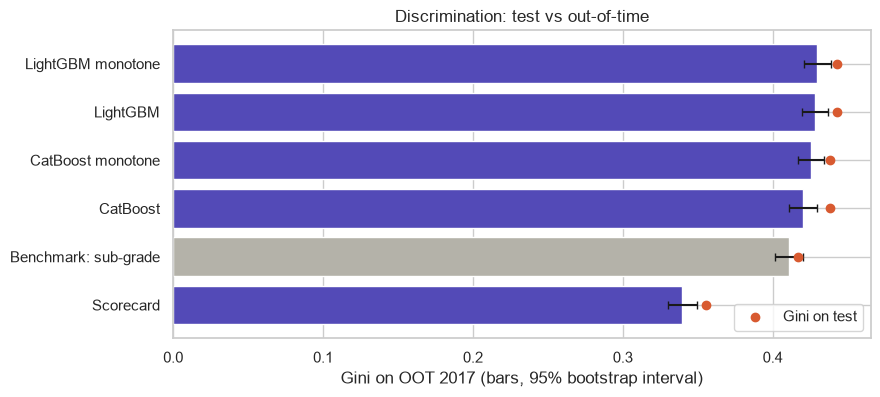

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
d = disc.sort_values("gini_oot")
colors = ["#B4B2A9" if m.startswith("Benchmark") else "#534AB7" for m in d.index]
ax.barh(d.index, d["gini_oot"], xerr=[d["gini_oot"] - d["ci_low"], d["ci_high"] - d["gini_oot"]],
        color=colors, capsize=3)
ax.scatter(d["gini_test"], range(len(d)), color="#D85A30", zorder=3, label="Gini on test")
ax.set_xlabel("Gini on OOT 2017 (bars, 95% bootstrap interval)")
ax.set_title("Discrimination: test vs out-of-time")
ax.legend(loc="lower right")
save(fig, "discrimination")
plt.show()

## 3. Does the model add information to the benchmark on OOT?

Same test as in notebook 04: combination weights fitted on the early-stopping holdout,
Gini measured on OOT.

In [7]:
def logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

sg_rate = train.groupby(train["sub_grade"].astype(str))[TARGET].mean()
def sg_logit(df):
    return logit(df["sub_grade"].astype(str).map(sg_rate).fillna(train[TARGET].mean()))

base_es, base_oot = sg_logit(parts["es"]), sg_logit(oot)
rows = [{"model": "Benchmark alone", "gini_oot": gini(y, base_oot)}]
for name in ["Scorecard", "LightGBM monotone", "CatBoost monotone"]:
    X_es = sm.add_constant(np.column_stack([base_es, logit(PD["es"][name])]))
    X_oot = sm.add_constant(np.column_stack([base_oot, logit(PD["oot"][name])]))
    comb = sm.Logit(Y["es"], X_es).fit(disp=0)
    rows.append({"model": f"Benchmark + {name}", "gini_oot": gini(y, comb.predict(X_oot))})
uplift = pd.DataFrame(rows).set_index("model")
uplift["uplift"] = uplift["gini_oot"] - uplift.loc["Benchmark alone", "gini_oot"]
uplift.round(4)

,gini_oot,uplift
model,,
Benchmark alone,0.4107,0.0000
Benchmark + Scorecard,0.4273,0.0166
Benchmark + LightGBM monotone,0.4650,0.0543
Benchmark + CatBoost monotone,0.4619,0.0513


## 4. Calibration

A PD model is used for pricing, provisions and capital, so the **level** of the PD matters,
not just the ranking. Development DR was 3.70%; OOT DR is 4.04%.

In [8]:
rows = []
for name in MODEL_NAMES:
    for part in ["test", "oot"]:
        p, yy = PD[part][name], Y[part]
        hl, hl_p = hosmer_lemeshow(yy, p, out_of_sample=True)
        ct = calibration_table(yy, p)
        rows.append({"model": name, "sample": part, "mean_pd": p.mean(), "default_rate": yy.mean(),
                     "ratio_observed_to_predicted": yy.mean() / p.mean(),
                     "deciles_failing_binomial_5pct": int((ct["binomial_p"] < 0.05).sum()),
                     "hosmer_lemeshow": hl, "hl_p_value": hl_p})
calib = pd.DataFrame(rows).set_index(["model", "sample"])
calib.round(4)

mean_pd  default_rate  ratio_observed_to_predicted  deciles_failing_binomial_5pct  hosmer_lemeshow  hl_p_value
model             sample                                                                                                                
Scorecard         test     0.0369        0.0370                       1.0010                              0          10.2409      0.4196
                  oot      0.0340        0.0404                       1.1887                              8         493.9045      0.0000
LightGBM          test     0.0368        0.0370                       1.0045                              1          14.7377      0.1419
                  oot      0.0386        0.0404                       1.0476                              6          51.3356      0.0000
LightGBM monotone test     0.0368        0.0370                       1.0046                              1          18.2944      0.0502
                  oot      0.0385        0.0404                       1.0506                              4          57.2074      0.0000
CatBoost          test     0.0367        0.0370                       1.0077                              1          15.1757      0.1258
                  oot      0.0386        0.0404                       1.0468                              5          73.1018      0.0000
CatBoost monotone test     0.0387        0.0370                       0.9557                              7          79.6586      0.0000
                  oot      0.0407        0.0404                       0.9924                              6          88.3428      0.0000

In [9]:
calibration_table(Y["oot"], PD["oot"]["LightGBM monotone"]).round(4)

,loans,defaults,mean_pd,default_rate,binomial_p
bucket,,,,,
1,29649,182,0.0063,0.0061,0.7414
2,29648,342,0.0118,0.0115,0.7065
3,29648,528,0.0165,0.0178,0.0791
4,29649,672,0.0213,0.0227,0.0946
5,29648,801,0.0264,0.0270,0.5383
6,29648,1074,0.0324,0.0362,0.0003
7,29649,1322,0.0398,0.0446,0.0000
8,29648,1620,0.0497,0.0546,0.0001
9,29648,2032,0.0657,0.0685,0.0489


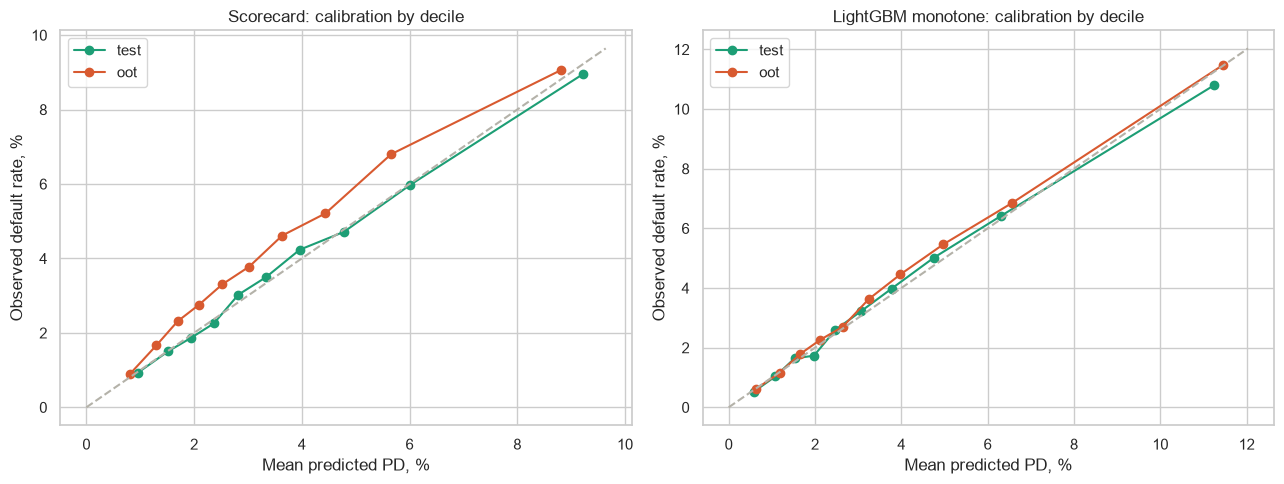

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, name in zip(axes, ["Scorecard", "LightGBM monotone"]):
    for part, color in [("test", "#1D9E75"), ("oot", "#D85A30")]:
        ct = calibration_table(Y[part], PD[part][name])
        ax.plot(ct["mean_pd"] * 100, ct["default_rate"] * 100, "o-", color=color, label=part)
    lim = max(ax.get_xlim()[1], ax.get_ylim()[1])
    ax.plot([0, lim], [0, lim], ls="--", color="#B4B2A9")
    ax.set_xlabel("Mean predicted PD, %")
    ax.set_ylabel("Observed default rate, %")
    ax.set_title(f"{name}: calibration by decile")
    ax.legend()
fig.tight_layout()
save(fig, "calibration")
plt.show()

### 4.1 Do the 2016 bureau fields distort calibration?

For loans issued before 2016 the 2016 fields are empty. If the boosting models learned
"missing = older, lower-risk loan", they would predict relatively higher PD where the fields
are filled. Compare the observed-to-predicted ratio by period: test before 2016, test 2016, OOT.

In [11]:
period = np.where(test["issue_d"] < "2016-01-01", "test, before 2016", "test, 2016")
rows = []
for name in MODEL_NAMES:
    for per in ["test, before 2016", "test, 2016"]:
        m = period == per
        rows.append({"model": name, "period": per, "mean_pd": PD["test"][name][m].mean(),
                     "default_rate": Y["test"][m].mean()})
    rows.append({"model": name, "period": "OOT 2017", "mean_pd": PD["oot"][name].mean(),
                 "default_rate": Y["oot"].mean()})
by_period = pd.DataFrame(rows)
by_period["observed_to_predicted"] = by_period["default_rate"] / by_period["mean_pd"]
by_period.pivot(index="model", columns="period", values="observed_to_predicted").round(3)

period,OOT 2017,"test, 2016","test, before 2016"
model,,,
CatBoost,1.047,1.025,0.993
CatBoost monotone,0.992,0.977,0.938
LightGBM,1.048,1.017,0.994
LightGBM monotone,1.051,1.015,0.996
Scorecard,1.189,1.166,0.892


## 5. Stability: has the population moved?

In [12]:
def score_psi(p_ref, p_new, n_bins=10):
    edges = np.unique(np.quantile(p_ref, np.linspace(0, 1, n_bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    return psi(pd.cut(p_ref, edges), pd.cut(p_new, edges))

stab = pd.DataFrame({name: {"psi_train_to_test": score_psi(PD["train"][name], PD["test"][name]),
                            "psi_train_to_oot": score_psi(PD["train"][name], PD["oot"][name])}
                     for name in MODEL_NAMES}).T
stab["status"] = pd.cut(stab["psi_train_to_oot"], [-1, PSI_MONITOR, PSI_SHIFT, 99],
                        labels=["stable", "monitor", "significant shift"])
stab.round(4)

,psi_train_to_test,psi_train_to_oot,status
Scorecard,0.0000,0.0267,stable
LightGBM,0.0000,0.0070,stable
LightGBM monotone,0.0000,0.0056,stable
CatBoost,0.0001,0.0062,stable
CatBoost monotone,0.0000,0.0063,stable


In [13]:
B_train = sc["binning"].transform(parts["train"], metric="bins")
B_oot = sc["binning"].transform(oot, metric="bins")
fpsi = pd.Series({f: psi(B_train[f], B_oot[f]) for f in sc["features"]}).sort_values(ascending=False)
fpsi_table = fpsi.to_frame("psi_train_to_oot")
fpsi_table["status"] = pd.cut(fpsi_table["psi_train_to_oot"], [-1, PSI_MONITOR, PSI_SHIFT, 99],
                              labels=["stable", "monitor", "significant shift"])
fpsi_table.round(4)

,psi_train_to_oot,status
il_util,5.9389,significant shift
mths_since_rcnt_il,5.9363,significant shift
inq_fi,5.9298,significant shift
percent_bc_gt_75,0.0538,stable
bc_open_to_buy,0.0477,stable
mo_sin_old_rev_tl_op,0.0287,stable
fico_range_low,0.0267,stable
verification_status,0.0246,stable
purpose,0.0185,stable
inq_last_6mths,0.0116,stable


The 2016 fields are "Not reported" for 61% of train loans and filled for every OOT loan,
so their PSI train → OOT is large by construction. Their stability is judged against
train loans issued in 2016 instead:

In [14]:
late_tr = parts["train"]["issue_d"] >= "2016-01-01"
late = [f for f in sc["features"] if f in sc["binning"].late]
pd.Series({f: psi(B_train.loc[late_tr, f], B_oot[f]) for f in late}, name="psi_2016_train_to_oot").round(4).to_frame()

,psi_2016_train_to_oot
mths_since_rcnt_il,0.0119
il_util,0.0156
inq_fi,0.0024


## 6. Robustness to the target reconstruction

Debt settlements make the payment schedule irregular, which is the main source of error in
the reconstructed 12-month target (notebook 01). Re-measure on OOT without them.

In [15]:
settled = oot["debt_settlement_flag"].eq("Y").to_numpy()
rows = []
for name in MODEL_NAMES + ["Benchmark: sub-grade"]:
    p = BENCH["oot"] if name.startswith("Benchmark") else PD["oot"][name]
    rows.append({"model": name, "gini_all": gini(y, p), "gini_without_settlements": gini(y[~settled], p[~settled])})
robust = pd.DataFrame(rows).set_index("model")
robust["difference"] = robust["gini_without_settlements"] - robust["gini_all"]
print(f"Settled loans in OOT: {settled.sum():,} ({settled.mean():.2%}); DR among them {y[settled].mean():.1%}")
robust.round(4)

Settled loans in OOT: 3,179 (1.07%); DR among them 40.0%


,gini_all,gini_without_settlements,difference
model,,,
Scorecard,0.3396,0.3372,-0.0024
LightGBM,0.4281,0.4266,-0.0015
LightGBM monotone,0.4298,0.4281,-0.0017
CatBoost,0.4203,0.4178,-0.0025
CatBoost monotone,0.4255,0.4229,-0.0026
Benchmark: sub-grade,0.4107,0.4097,-0.0010


## 7. Interpretability: what drives the boosting model?

SHAP values of LightGBM monotone on a random 20,000 OOT loans, compared with the features
that move the scorecard most (points range from notebook 04). A boosting model that relied on
drivers absent from the scorecard, or with no business meaning, would be a finding.

In [16]:
sample_idx = np.random.default_rng(SEED).choice(len(oot), 20_000, replace=False)
X_shap = lgb_frame(oot.iloc[sample_idx])
explainer = shap.TreeExplainer(boosters["LightGBM monotone"])
sv = explainer.shap_values(X_shap)
sv = sv[1] if isinstance(sv, list) else sv
shap_imp = pd.Series(np.abs(sv).mean(axis=0), index=FEATURES).sort_values(ascending=False)

points = pd.read_csv(TABLES / "04_scorecard_points.csv")
pts_range = points.groupby("feature")["points"].agg(lambda s: s.max() - s.min())
top = shap_imp.head(15).to_frame("mean_abs_shap")
top["in_scorecard"] = top.index.isin(sc["features"])
top["scorecard_points_range"] = pts_range.reindex(top.index)
top.round(4)

C:\Users\Alex\miniconda3\envs\ml\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


,mean_abs_shap,in_scorecard,scorecard_points_range
dti,0.2112,True,18.6
loan_amnt,0.1899,False,NaN
acc_open_past_24mths,0.1731,True,17.9
fico_range_low,0.1414,True,13.4
percent_bc_gt_75,0.1199,True,10.7
purpose,0.1138,True,16.6
mths_since_recent_inq,0.1108,True,15.0
annual_inc,0.1092,True,4.5
mths_since_rcnt_il,0.0997,True,11.4
total_il_high_credit_limit,0.0874,False,NaN


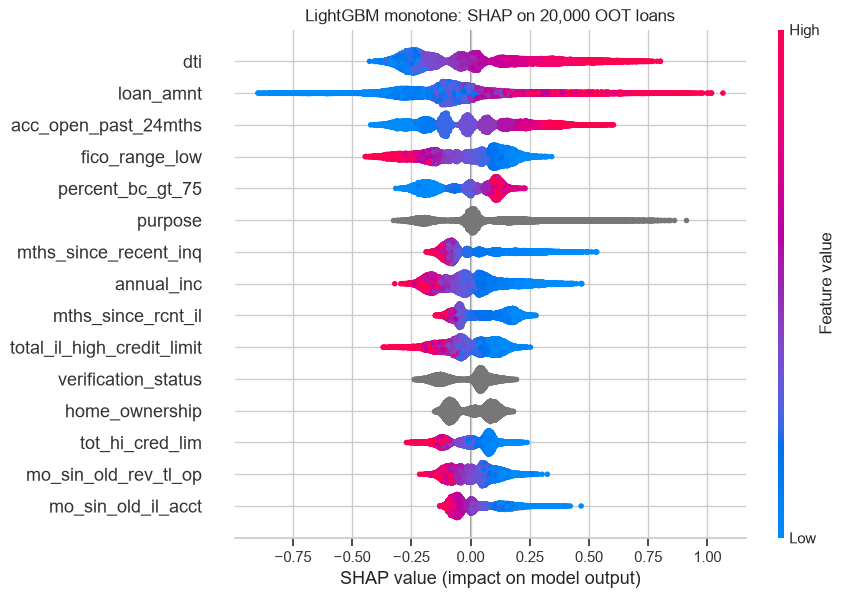

In [17]:
fig = plt.figure()
shap.summary_plot(sv, X_shap, max_display=15, show=False, plot_size=(9, 6))
plt.title("LightGBM monotone: SHAP on 20,000 OOT loans")
save(plt.gcf(), "shap")
plt.show()

## 8. Fairness

Lending Club data contains **no protected characteristics** (race, sex, age), so fairness
cannot be measured directly. Geography is a known proxy for race and ethnicity in the US,
which is why `zip_code` and `addr_state` were kept out of every model (notebook 01). The tests
here check that the model works **equally well across states**:

* Gini and calibration (observed / predicted) by state;
* approval rate at a fixed cut-off and the **adverse impact ratio** (approval rate of a state
  divided by the highest one; below 0.8 fails the four-fifths rule).

The cut-off approves 85% of applicants: the PD at the 85th percentile of train predictions.
States with at least 5,000 OOT loans are shown. A full fair-lending analysis would infer
protected classes (for example with BISG on census data); that is out of scope and listed as
a limitation.

In [18]:
rows = []
for name in ["Scorecard", "LightGBM monotone"]:
    cutoff = np.quantile(PD["train"][name], 0.85)
    approved = PD["oot"][name] <= cutoff
    for st, idx in oot.groupby("addr_state").indices.items():
        if len(idx) < 5000:
            continue
        rows.append({"model": name, "state": st, "loans": len(idx), "gini": gini(y[idx], PD["oot"][name][idx]),
                     "observed_to_predicted": y[idx].mean() / PD["oot"][name][idx].mean(),
                     "approval_rate": approved[idx].mean(),
                     "dr_of_approved": y[idx][approved[idx]].mean()})
fair = pd.DataFrame(rows)
fair["adverse_impact_ratio"] = fair["approval_rate"] / fair.groupby("model")["approval_rate"].transform("max")
fair_summary = fair.groupby("model").agg(states=("state", "size"),
                                         gini_min=("gini", "min"), gini_max=("gini", "max"),
                                         calib_min=("observed_to_predicted", "min"),
                                         calib_max=("observed_to_predicted", "max"),
                                         air_min=("adverse_impact_ratio", "min"))
fair_summary["air_fails"] = fair.assign(f=fair["adverse_impact_ratio"] < MIN_AIR).groupby("model")["f"].sum()
fair_summary.round(3)

,states,gini_min,gini_max,calib_min,calib_max,air_min,air_fails
model,,,,,,,
LightGBM monotone,19,0.362,0.485,0.752,1.221,0.961,0
Scorecard,19,0.241,0.405,0.845,1.411,0.951,0


In [19]:
fair[fair["model"] == "LightGBM monotone"].sort_values("adverse_impact_ratio").round(3)

,model,state,loans,gini,observed_to_predicted,approval_rate,dr_of_approved,adverse_impact_ratio
23,LightGBM monotone,FL,21900,0.434,1.155,0.823,0.033,0.961
24,LightGBM monotone,GA,9417,0.434,0.761,0.826,0.021,0.965
37,LightGBM monotone,WA,5974,0.466,0.836,0.828,0.021,0.967
28,LightGBM monotone,MI,7686,0.479,0.967,0.833,0.027,0.972
35,LightGBM monotone,TX,25165,0.465,1.120,0.833,0.030,0.973
21,LightGBM monotone,CO,6188,0.449,0.904,0.837,0.024,0.977
20,LightGBM monotone,CA,41547,0.441,1.221,0.839,0.033,0.980
33,LightGBM monotone,OH,9426,0.445,0.947,0.840,0.027,0.981
19,LightGBM monotone,AZ,7126,0.362,1.019,0.840,0.031,0.981
30,LightGBM monotone,NC,7957,0.485,1.066,0.843,0.026,0.984


## 9. Save

In [20]:
disc.round(5).to_csv(TABLES / "05_discrimination.csv")
vs_bench.round(5).to_csv(TABLES / "05_vs_benchmark.csv")
calib.round(5).to_csv(TABLES / "05_calibration.csv")
stab.round(5).to_csv(TABLES / "05_score_psi.csv")
fpsi_table.round(5).to_csv(TABLES / "05_feature_psi.csv")
fair.round(5).to_csv(TABLES / "05_fairness_by_state.csv", index=False)
print("saved")

saved


## 10. Findings and verdict

### Summary of results on OOT 2017
| Model | Gini OOT (95% CI) | vs benchmark | Drop test → OOT | Observed / predicted PD | Score PSI |
|---|---|---|---|---|---|
| Scorecard | 0.340 (0.330–0.349) | −0.071 (significant) | 1.6 pp | 1.19 | 0.027 |
| LightGBM | 0.428 (0.419–0.437) | +0.018 (significant) | 1.5 pp | 1.05 | 0.007 |
| **LightGBM monotone** | **0.430 (0.421–0.439)** | **+0.019 (significant)** | 1.3 pp | 1.05 | 0.006 |
| CatBoost | 0.420 (0.411–0.430) | +0.010 (significant) | 1.8 pp | 1.05 | 0.006 |
| CatBoost monotone | 0.426 (0.417–0.434) | +0.015 (significant) | 1.2 pp | 0.99 | 0.006 |
| Benchmark: sub-grade | 0.411 (0.402–0.420) | — | 0.6 pp | — | — |

- **Ranking holds on new borrowers.** Every model loses less than 2 pp of Gini from test to
  OOT (threshold 5 pp), and Gini is flat across the four quarters of 2017.
- **The population is stable:** score PSI ≤ 0.03 for every model; feature PSI ≤ 0.06 (the
  2016 fields, compared with 2016 train loans, ≤ 0.016).
- **Calibration is the weak point:** default rates rose from 3.70% in development to 4.04% in
  2017, and every model except CatBoost monotone under-predicts.

### Severity scale
* **High:** the model must not be used for the stated purpose until resolved.
* **Medium:** use is possible with conditions or compensating controls; resolve within an
  agreed timeframe.
* **Low:** improvement or documentation point.

### Findings
| ID | Severity | Models | Finding | Evidence | Recommendation |
|---|---|---|---|---|---|
| F1 | **High** | Scorecard | Discrimination below the benchmark | OOT Gini 0.340 vs Lending Club sub-grade 0.411 (difference -0.071, 95% CI -0.081 to -0.061). Fails the success criterion. | Not to be used as the primary decision score. Can be used alongside the existing grade (+0.017 Gini when combined). |
| F2 | **High** | Scorecard | PD under-predicted on OOT | Observed / predicted 1.19 (mean PD 3.40% vs default rate 4.04%); 8 of 10 deciles fail the binomial test; Hosmer-Lemeshow p < 0.001. | Recalibrate the intercept to the latest observed default rate and add a margin of conservatism before any PD use (pricing, provisions, capital). |
| F3 | **Medium** | LightGBM, CatBoost | PD moderately under-predicted on OOT | Observed / predicted 1.05 for LightGBM monotone; 4 of 10 deciles fail the binomial test (deciles 6-8). CatBoost monotone is the best calibrated (0.99). | Recalibrate (e.g. intercept shift on the most recent matured cohort) before PD use; monitor the observed / predicted ratio quarterly. |
| F4 | **Medium** | All | Structural break in the 2016 bureau fields drives calibration drift | Scorecard observed / predicted is 0.89 on test loans issued before 2016 and 1.17 on 2016 loans: the model is fitted on a mixture of periods with and without these fields, while every OOT loan has them. | Re-estimate (or at least recalibrate) on 2016+ loans once enough matured history is available; document the design choice. |
| F5 | **Medium** | All | Target is a reconstruction, not observed 90+ dpd | Default month is derived from instalments paid (96.3% agreement with the date method on matured loans). Cured delinquencies are invisible. Results are robust to removing debt settlements (Gini changes by at most 0.003). | Accepted for development on public data; in production, validate against actual delinquency history. |
| F6 | **Medium** | LightGBM, CatBoost | Main boosting driver absent from the scorecard | loan_amnt is the 2nd most important feature by SHAP, but was excluded from the scorecard (IV 0.015, non-monotonic) and is unconstrained in boosting. | Document the business rationale of its effect and check its shape (partial dependence) before use; include it in adverse-action reason codes. |
| F7 | **Medium** | All | Fairness assessment incomplete | No protected characteristics in the data. By state: adverse impact ratio >= 0.95 (passes the four-fifths rule), but calibration varies from 0.75 to 1.22 observed / predicted. | Before deployment, run a fair-lending analysis with inferred protected classes (e.g. BISG); monitor state-level calibration. |
| F8 | **Low** | LightGBM, CatBoost | Development optimism and incomplete tuning | LightGBM tuning and early stopping used the same holdout (Gini 0.458 there vs 0.443 on test); CatBoost was not tuned. Boosting in-sample Gini 0.52-0.59 vs test 0.44. | Use a separate tuning holdout in the next development cycle; tune CatBoost before final champion selection. |
| F9 | **Low** | All | Data limitations | 2013-2017 contains no recession (PD is not through-the-cycle); only funded loans are observed (no reject inference); joint applications excluded. | State in the model documentation; apply a downturn adjustment if the PD is used for capital. |

### Verdict
| Model | Verdict | Conditions |
|---|---|---|
| Scorecard (logistic WoE) | **Not approved** as the primary application score | F1, F2. May be used as an explainable supplement to the existing grade. |
| **LightGBM monotone** | **Approved with conditions** as the champion for ranking applicants | Recalibrate before PD use (F3); document `loan_amnt` (F6); fair-lending analysis before deployment (F7); monitoring plan below. |
| CatBoost monotone | **Approved with conditions** as the challenger | Same conditions; best calibrated, tune before a final champion decision (F8). |
| LightGBM, CatBoost (unconstrained) | **Not recommended** | Same accuracy as the monotone versions, less explainable behaviour. |

### Monitoring plan
| Metric | Frequency | Amber | Red |
|---|---|---|---|
| Score PSI vs development | quarterly | > 0.10 | > 0.25 |
| Feature PSI (model inputs) | quarterly | > 0.10 | > 0.25 |
| Gini on each cohort after 12 months | quarterly | drop > 3 pp | drop > 5 pp |
| Observed / predicted PD | quarterly | outside 0.9–1.1 | outside 0.8–1.2 |
| Adverse impact ratio by state | semi-annually | < 0.9 | < 0.8 |

Red on any metric triggers a model review; two consecutive ambers trigger recalibration.